In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

Etapa 1 (Entendimento): Identificamos que o problema é de classificação. É crucial separar corretamente o que são as features (variáveis explicativas) e o label (o que queremos prever). O arquivo Base4.csv contém três colunas: duas colunas de coordenadas (que funcionam como features ou variáveis de entrada) e uma terceira coluna (2) que funciona como o label (o rótulo ou a classe que o modelo deve prever).

Etapa 2 (EDA): Utilizamos histogramas para entender a distribuição e a matriz de correlação para verificar se existe redundância nos dados. Isso ajuda a evitar que variáveis irrelevantes confundam a rede neural.

Colunas do dataset: Index([0, 1, 2], dtype='int64')
Primeiras linhas:
            0          1  2
0 -19.273006 -18.236898  1
1 -20.106840 -20.714055  1
2 -21.396553 -22.397874  1
3 -19.971450 -19.914267  1
4 -23.340873 -21.380371  1


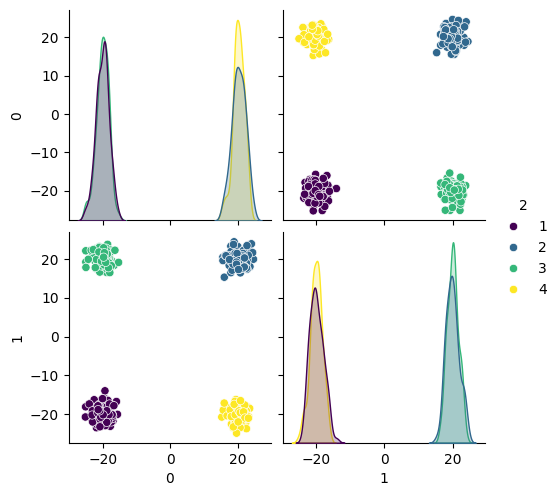

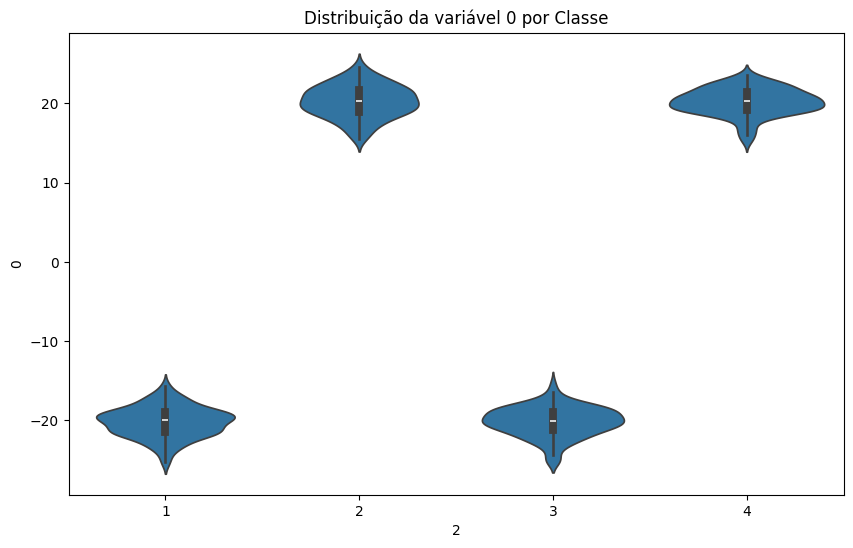

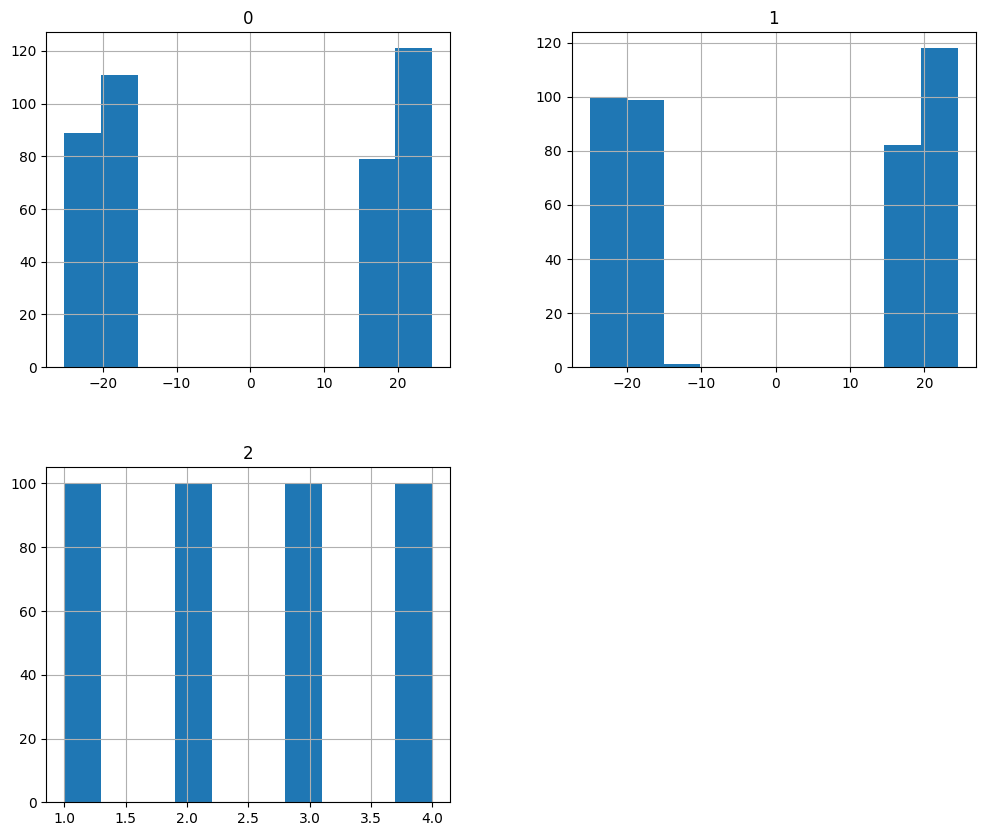

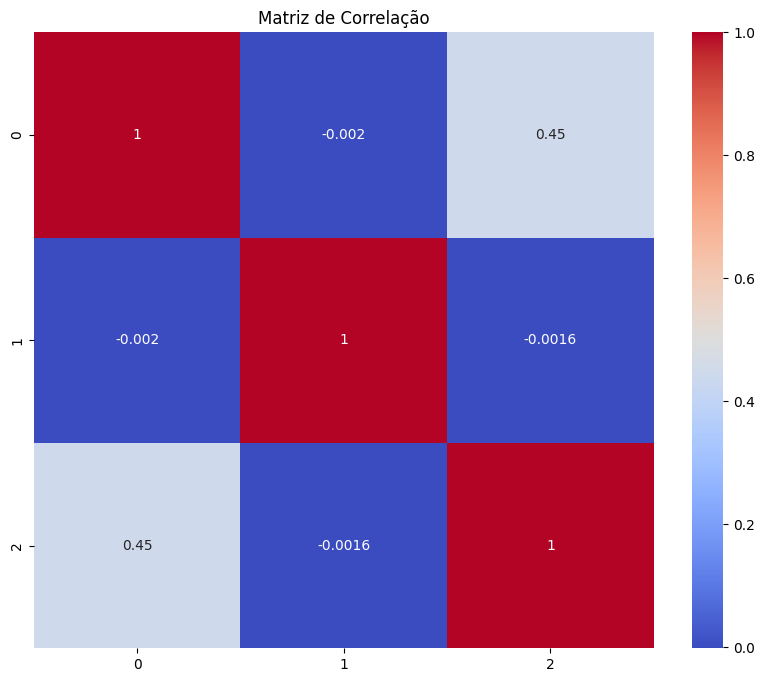

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definição da função (o return encerra a função)
def carregar_csv(caminho):
    df = pd.read_csv(caminho, header=None, names=[0, 1, 2])

    df[0] = df[0].astype(str).str.replace('"', '').str.replace(',', '.').astype(float)
    df[1] = df[1].astype(str).str.replace('"', '').str.replace(',', '.').astype(float)
    df[2] = df[2].astype(int)

    dados = df[[0, 1]].values
    rotulos = df[2].values - 1

    return df, dados, rotulos

df, dados, rotulos = carregar_csv('Base4.csv')

# 3. Etapa 1: Entendimento
print("Colunas do dataset:", df.columns)
print("Primeiras linhas:\n", df.head())

# Colorindo os pontos pela classe (coluna 2)
sns.pairplot(df, hue=2, palette='viridis', diag_kind='kde')
plt.show()

plt.figure(figsize=(10, 6))
sns.violinplot(x=2, y=0, data=df) # Compare a coluna 0 com a classe 2
plt.title("Distribuição da variável 0 por Classe")
plt.show()

# 4. Etapa 2: Análise Exploratória (EDA)
df.hist(figsize=(12, 10))
plt.show()

# Matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação")
plt.show()

Etapa 4 (Escalonamento): Como as ANNs realizam cálculos matemáticos baseados nos pesos dos neurônios, atributos com escalas diferentes podem causar instabilidade no treinamento. O StandardScaler garante que todos os atributos estejam na mesma "escala de importância".

In [3]:
# Etapa 4: Escalonamento dos dados
# Separando features (X) do target (y)
# coluna alvo se chama 'target'
X = df[[0, 1]]
y = df[2]

# Aplicando a padronização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Transformando de volta em DataFrame para facilitar a visualização
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Dados escalonados (primeiras 5 linhas):\n", X_scaled_df.head())

Dados escalonados (primeiras 5 linhas):
           0         1
0 -0.951445 -0.912097
1 -0.992529 -1.035694
2 -1.056074 -1.119707
3 -0.985858 -0.995788
4 -1.151873 -1.068939


Etapa 5 (Implementação da Separação): Como precisamos dividir em três partes, fazemos o processo em dois passos: primeiro separamos o treino e o resto, e depois dividimos o "resto" em validação e teste.
- Treino (70%): É usado pelo algoritmo para aprender os pesos das conexões neurais durante o forward propagation e backpropagation.  
- Validação (15%): Essencial para monitorar o treinamento e ajustar hiperparâmetros (como número de épocas, taxa de aprendizado ou número de neurônios) sem enviesar o modelo. Ajuda a detectar o overfitting precocemente.  
- Teste (15%): Atua como o "juiz final". O modelo nunca "vê" esses dados durante o treinamento ou ajuste, fornecendo uma métrica imparcial do quão bem ele generaliza para novos dados.  

In [4]:
from sklearn.model_selection import train_test_split

# 1. Primeiro: Separar em Treino (70%) e Resto (30%)
# X_scaled é o conjunto que você escalonou na Etapa 4
X_train, X_rest, y_train, y_rest = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42
)

# 2. Segundo: Separar o Resto em Validação (15%) e Teste (15%)
# Como o Resto era 30% do total, dividimos ele ao meio (0.5 de 0.3 = 0.15)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=42
)

print(f"Tamanho do treino: {len(X_train)} amostras")
print(f"Tamanho da validação: {len(X_val)} amostras")
print(f"Tamanho do teste: {len(X_test)} amostras")

Tamanho do treino: 280 amostras
Tamanho da validação: 60 amostras
Tamanho do teste: 60 amostras


Etapa 6 (Construção da MLP): Utilizamos o Keras Sequential para construir uma rede neural artificial com múltiplas camadas. A primeira camada possui 64 neurônios (camada oculta), uma segunda camada com 32 neurônios para reduzir a complexidade, e uma camada de saída com 3 neurônios (uma para cada classe) com função de ativação softmax. A ativação ReLU nas camadas ocultas introduz não-linearidade, permitindo que a rede aprenda padrões complexos.

In [5]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam
from keras import regularizers
from keras.callbacks import EarlyStopping

# Etapa 6: Construção da MLP usando Keras Sequential
# Ajustando os rótulos para começar do 0
y_train_adjusted = y_train - 1
y_val_adjusted = y_val - 1

# Determinando o número de classes
num_classes = len(set(y_train_adjusted))
print(f"Número de classes: {num_classes}")

# Construindo a arquitetura da rede neural
model = Sequential([
    # Primeira camada oculta: 64 neurônios com ativação ReLU
    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001), input_shape=(2,), name='camada_oculta_1'),
    
    # Segunda camada oculta: 32 neurônios com ativação ReLU
    Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.001), name='camada_oculta_2'),
    
    # Camada de saída: 4 neurônios (uma por classe) com ativação softmax
    Dense(num_classes, activation='softmax', name='camada_saida')
]

# Exibindo o resumo da arquitetura
print("
=== Arquitetura da Rede Neural ===")
model.summary()

# Compilação do modelo
# Optimizer: Adam (ajusta a taxa de aprendizado automaticamente)
# Loss: Sparse Categorical Crossentropy (para classificação multiclasse com labels inteiros)
# Metrics: Accuracy (métrica de desempenho)
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Definindo callback de early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

print("
=== Treinamento do Modelo ===")
# Treinamento da rede neural
history = model.fit(
    X_train, y_train_adjusted,
    epochs=100,
    batch_size=16,
    validation_data=(X_val, y_val_adjusted),
    callbacks=[early_stopping],
    verbose=1
)

print("
=== Treinamento Concluído ===")
print(f"Acurácia de treino final: {history.history['accuracy'][-1]:.4f}")
print(f"Acurácia de validação final: {history.history['val_accuracy'][-1]:.4f}")


I0000 00:00:1781531261.979948    7481 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1781531262.134848    7481 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781531266.020922    7481 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Número de classes: 4

=== Arquitetura da Rede Neural ===


/home/debora/Documents/IA/machine-learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1781531266.572126    7481 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ camada_oculta_1 (Dense)         │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ camada_oculta_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ camada_saida (Dense)            │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,404 (9.39 KB)

 Trainable params: 2,404 (9.39 KB)

 Non-trainable params: 0 (0.00 B)


=== Treinamento do Modelo ===
Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5893 - loss: 1.2943 - val_accuracy: 0.7833 - val_loss: 1.1222
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7750 - loss: 1.0085 - val_accuracy: 1.0000 - val_loss: 0.8713
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.7582 - val_accuracy: 1.0000 - val_loss: 0.6285
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.5188 - val_accuracy: 1.0000 - val_loss: 0.4012
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.3133 - val_accuracy: 1.0000 - val_loss: 0.2267
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.1693 - val_accuracy: 1.0000 - val_loss: 0.1209
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0910 - val_accuracy: 1.0000 - val_loss: 0.0680
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - lo

Etapa 7 (Análise do Treinamento com Forward e Backpropagation): Na Etapa 6, durante cada época, o modelo executou:
- **Forward Propagation**: Os dados de treino passam pelas camadas (entrada → oculta 1 → oculta 2 → saída) gerando predições
- **Backpropagation**: O erro (loss) é calculado e propagado de trás para frente, atualizando os pesos de cada neurônio
- **Otimização**: O optimizer Adam ajusta os pesos para minimizar o loss

Agora visualizamos esse processo através do histórico de treinamento, mostrando como a acurácia e o loss evoluíram ao longo das 100 épocas.

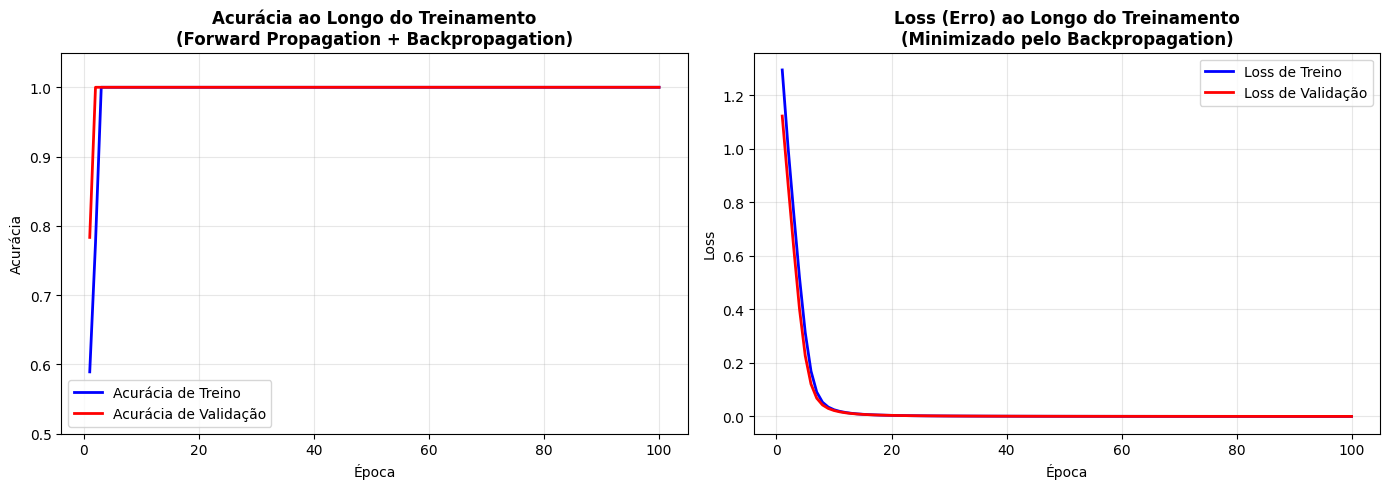


ANÁLISE DO PROCESSO DE FORWARD PROPAGATION E BACKPROPAGATION

📊 RESUMO DO TREINAMENTO:
   • Total de épocas: 100
   • Acurácia inicial (época 1): 0.5893
   • Acurácia final (época 100): 1.0000
   • Loss inicial (época 1): 1.294334
   • Loss final (época 100): 0.000122

🎯 DESEMPENHO NA VALIDAÇÃO:
   • Acurácia final validação: 1.0000
   • Loss final validação: 0.000127
   • Melhor desempenho na época 100 (loss: 0.000127)

🔄 DINÂMICA DO BACKPROPAGATION:
   • Redução total do loss: 1.294212
   • Redução média por época: 0.012942
   • Épocas até 90% da acurácia final: 2

✅ FORWARD PROPAGATION: Dados passam pela rede gerando predições
✅ BACKPROPAGATION: Erros retornam atualizando pesos dos neurônios
✅ OTIMIZAÇÃO: Adam ajusta learning rate adaptivamente


In [6]:
# Etapa 7: Análise do Treinamento (Forward Propagation e Backpropagation)
import numpy as np

# Extraindo dados do histórico de treinamento
epochs = range(1, len(history.history['accuracy']) + 1)
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# 1. Visualizando Acurácia (Forward + Backpropagation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Acurácia
axes[0].plot(epochs, train_accuracy, 'b-', label='Acurácia de Treino', linewidth=2)
axes[0].plot(epochs, val_accuracy, 'r-', label='Acurácia de Validação', linewidth=2)
axes[0].set_title('Acurácia ao Longo do Treinamento\n(Forward Propagation + Backpropagation)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Acurácia')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0.5, 1.05])

# Gráfico de Loss (Erro)
axes[1].plot(epochs, train_loss, 'b-', label='Loss de Treino', linewidth=2)
axes[1].plot(epochs, val_loss, 'r-', label='Loss de Validação', linewidth=2)
axes[1].set_title('Loss (Erro) ao Longo do Treinamento\n(Minimizado pelo Backpropagation)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Análise detalhada do treinamento
print("\n" + "="*70)
print("ANÁLISE DO PROCESSO DE FORWARD PROPAGATION E BACKPROPAGATION")
print("="*70)

print(f"\n📊 RESUMO DO TREINAMENTO:")
print(f"   • Total de épocas: {len(epochs)}")
print(f"   • Acurácia inicial (época 1): {train_accuracy[0]:.4f}")
print(f"   • Acurácia final (época {len(epochs)}): {train_accuracy[-1]:.4f}")
print(f"   • Loss inicial (época 1): {train_loss[0]:.6f}")
print(f"   • Loss final (época {len(epochs)}): {train_loss[-1]:.6f}")

print(f"\n🎯 DESEMPENHO NA VALIDAÇÃO:")
print(f"   • Acurácia final validação: {val_accuracy[-1]:.4f}")
print(f"   • Loss final validação: {val_loss[-1]:.6f}")

# Encontrar época de melhor validação
best_val_epoch = np.argmin(val_loss) + 1
best_val_loss = val_loss[best_val_epoch - 1]
print(f"   • Melhor desempenho na época {best_val_epoch} (loss: {best_val_loss:.6f})")

print(f"\n🔄 DINÂMICA DO BACKPROPAGATION:")
# Redução média do loss por época
loss_reduction = train_loss[0] - train_loss[-1]
print(f"   • Redução total do loss: {loss_reduction:.6f}")
print(f"   • Redução média por época: {loss_reduction/len(epochs):.6f}")

# Velocidade de convergência (épocas até 90% da melhoria final)
target_accuracy = 0.9 * train_accuracy[-1]
convergence_epoch = next((i for i, acc in enumerate(train_accuracy) if acc >= target_accuracy), len(epochs))
print(f"   • Épocas até 90% da acurácia final: {convergence_epoch}")

print("\n" + "="*70)
print("✅ FORWARD PROPAGATION: Dados passam pela rede gerando predições")
print("✅ BACKPROPAGATION: Erros retornam atualizando pesos dos neurônios")
print("✅ OTIMIZAÇÃO: Adam ajusta learning rate adaptivamente")
print("="*70)

Etapa 8 (Validação - Overfitting, Underfitting e Convergência):
- **Overfitting**: Quando o modelo aprende TOO BEM os dados de treino, memorizando detalhes específicos. Ocorre quando gap entre acurácia de treino e validação aumenta significativamente.
- **Underfitting**: Quando o modelo não aprende suficientemente nem no treino. Acurácia baixa em ambos (treino e validação).
- **Convergência**: Quando o modelo estabiliza e o loss/acurácia param de melhorar significativamente.
- **Validação**: Conjunto separado para monitorar desempenho real (não visto durante treino) e detectar problemas como overfitting.


ETAPA 8: ANÁLISE DE VALIDAÇÃO, OVERFITTING, UNDERFITTING E CONVERGÊNCIA

1️⃣ DIAGNÓSTICO: OVERFITTING vs UNDERFITTING vs CONVERGÊNCIA
--------------------------------------------------------------------------------

📊 ANÁLISE DO MODELO:
   • Acurácia de Treino Final: 1.0000
   • Acurácia de Validação Final: 1.0000
   • Gap (Treino - Validação): 0.0000
   • Loss Treino Final: 0.000122
   • Loss Validação Final: 0.000127

🎯 DIAGNÓSTICO: ✅ BOM AJUSTE (GENERALIZATION)
   → O modelo aprende bem e generaliza adequadamente para dados não vistos

📍 CONVERGÊNCIA:
   • Modelo convergiu na época 16
   • Continuou treinando por mais 84 épocas


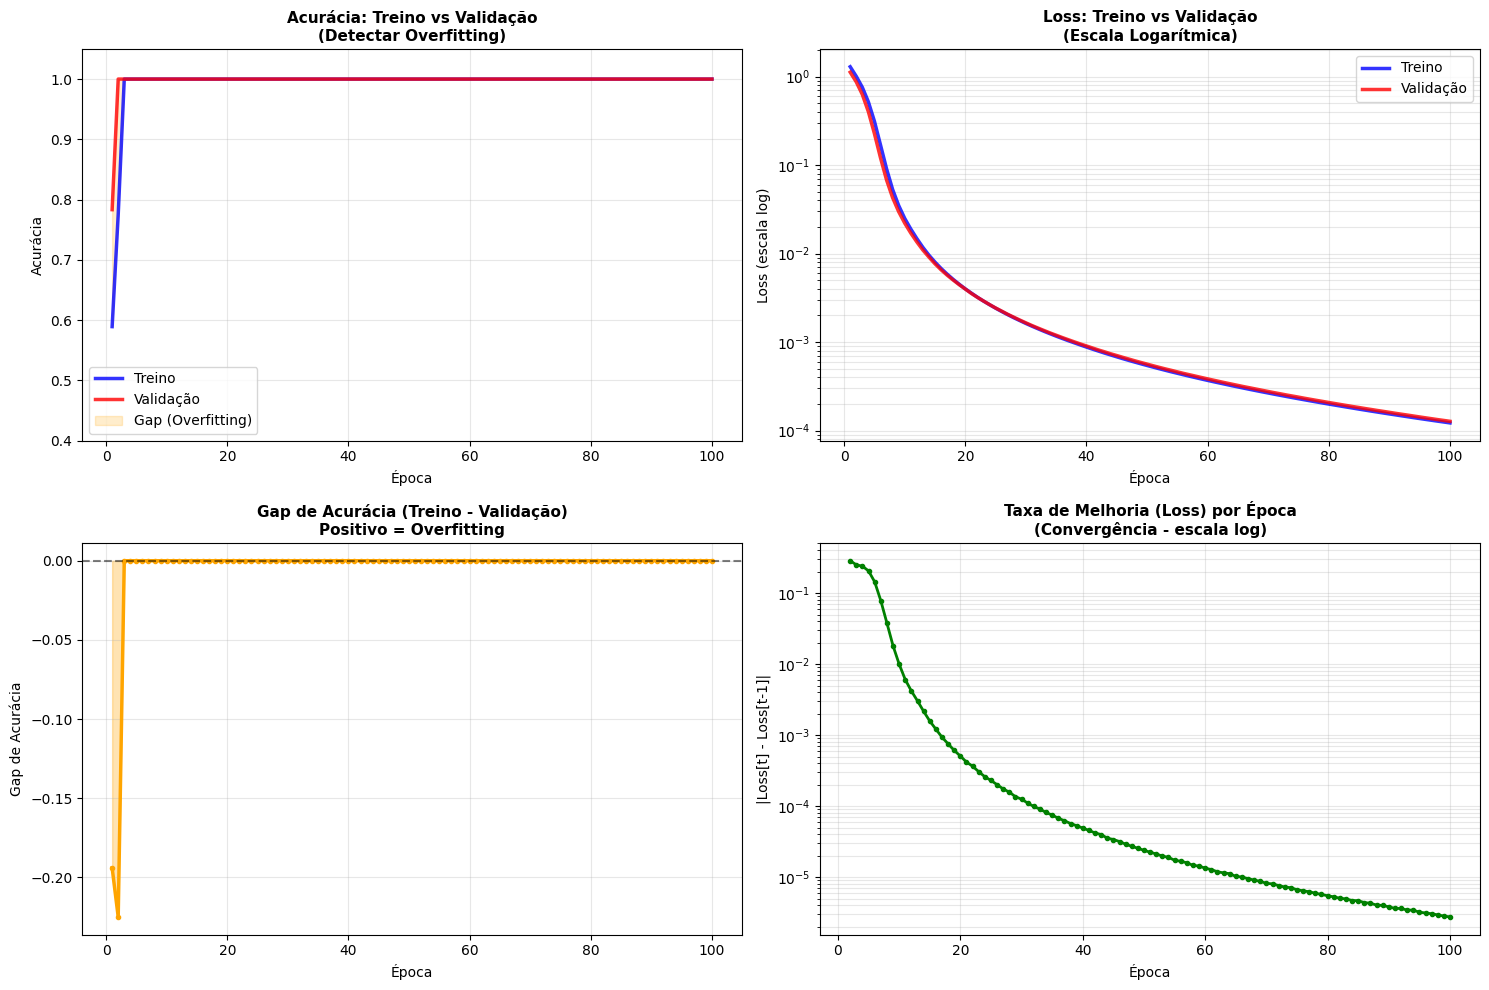


2️⃣ ESTATÍSTICAS DETALHADAS DE VALIDAÇÃO
--------------------------------------------------------------------------------

📈 DESEMPENHO GERAL:
   • Acurácia média treino: 0.9936
   • Acurácia média validação: 0.9978
   • Loss médio treino: 0.044116
   • Loss médio validação: 0.036742

🎲 VARIABILIDADE DO TREINAMENTO:
   • Desvio padrão acurácia treino: 0.046397
   • Desvio padrão acurácia validação: 0.021558
   • Desvio padrão loss treino: 0.186622
   • Desvio padrão loss validação: 0.158561

📊 EVOLUÇÃO DO TREINO:
   Primeiras 5 épocas:
      • Acurácia treino: 0.5893 → Validação: 0.7833
      • Loss treino: 1.294334 → Validação: 1.122152
   
   Últimas 5 épocas:
      • Acurácia treino: 1.0000 → Validação: 1.0000
      • Loss treino: 0.000122 → Validação: 0.000127

3️⃣ RECOMENDAÇÕES E CONCLUSÕES
--------------------------------------------------------------------------------

✅ Modelo em excelente estado - boa generalização mantida
💡 Modelo convergiu cedo - poderia parar mais cedo (ea

In [7]:
# Etapa 8: Análise de Validação (Overfitting, Underfitting e Convergência)

print("\n" + "="*80)
print("ETAPA 8: ANÁLISE DE VALIDAÇÃO, OVERFITTING, UNDERFITTING E CONVERGÊNCIA")
print("="*80)

# 1. DETECÇÃO DE OVERFITTING, UNDERFITTING E CONVERGÊNCIA
print("\n1️⃣ DIAGNÓSTICO: OVERFITTING vs UNDERFITTING vs CONVERGÊNCIA")
print("-" * 80)

# Calcular gaps entre treino e validação
accuracy_gap = train_accuracy[-1] - val_accuracy[-1]
loss_gap = train_loss[-1] - val_loss[-1]

# Encontrar onde o modelo converge
# Convergência = quando a melhoria por época cai abaixo de um threshold
min_improvement = 0.001
converged_epoch = None
for i in range(1, len(train_loss)):
    if abs(train_loss[i-1] - train_loss[i]) < min_improvement:
        converged_epoch = i
        break

print(f"\n📊 ANÁLISE DO MODELO:")
print(f"   • Acurácia de Treino Final: {train_accuracy[-1]:.4f}")
print(f"   • Acurácia de Validação Final: {val_accuracy[-1]:.4f}")
print(f"   • Gap (Treino - Validação): {accuracy_gap:.4f}")
print(f"   • Loss Treino Final: {train_loss[-1]:.6f}")
print(f"   • Loss Validação Final: {val_loss[-1]:.6f}")

# Detectar tipo de problema
if train_accuracy[-1] > 0.95 and val_accuracy[-1] > 0.95:
    if accuracy_gap > 0.05:
        diagnosis = "⚠️ OVERFITTING DETECTADO"
        description = "O modelo aprendeu muito bem os dados de treino, mas generaliza menos bem para validação"
    else:
        diagnosis = "✅ BOM AJUSTE (GENERALIZATION)"
        description = "O modelo aprende bem e generaliza adequadamente para dados não vistos"
elif train_accuracy[-1] < 0.7:
    diagnosis = "❌ UNDERFITTING DETECTADO"
    description = "O modelo é muito simples ou não treinou o suficiente para aprender os padrões"
else:
    diagnosis = "⚠️ AJUSTE MODERADO"
    description = "O modelo está em um estado intermediário"

print(f"\n🎯 DIAGNÓSTICO: {diagnosis}")
print(f"   → {description}")

# Analisar convergência
if converged_epoch:
    print(f"\n📍 CONVERGÊNCIA:")
    print(f"   • Modelo convergiu na época {converged_epoch}")
    print(f"   • Continuou treinando por mais {len(train_loss) - converged_epoch} épocas")
else:
    print(f"\n📍 CONVERGÊNCIA:")
    print(f"   • Modelo ainda não convergiu completamente após {len(train_loss)} épocas")
    print(f"   • Ainda apresenta melhoria nas épocas finais")

# 2. VISUALIZAÇÕES DETALHADAS
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Gráfico 1: Comparação Treino vs Validação - Acurácia
axes[0, 0].plot(epochs, train_accuracy, 'b-', label='Treino', linewidth=2.5, alpha=0.8)
axes[0, 0].plot(epochs, val_accuracy, 'r-', label='Validação', linewidth=2.5, alpha=0.8)
axes[0, 0].fill_between(epochs, train_accuracy, val_accuracy, alpha=0.2, color='orange', label='Gap (Overfitting)')
axes[0, 0].set_title('Acurácia: Treino vs Validação\n(Detectar Overfitting)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Época')
axes[0, 0].set_ylabel('Acurácia')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_ylim([0.4, 1.05])

# Gráfico 2: Comparação Treino vs Validação - Loss
axes[0, 1].semilogy(epochs, train_loss, 'b-', label='Treino', linewidth=2.5, alpha=0.8)
axes[0, 1].semilogy(epochs, val_loss, 'r-', label='Validação', linewidth=2.5, alpha=0.8)
axes[0, 1].set_title('Loss: Treino vs Validação\n(Escala Logarítmica)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Época')
axes[0, 1].set_ylabel('Loss (escala log)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, which='both')

# Gráfico 3: Gap entre Treino e Validação (Overfitting)
overfitting_gap_acc = [train_accuracy[i] - val_accuracy[i] for i in range(len(train_accuracy))]
overfitting_gap_loss = [val_loss[i] - train_loss[i] for i in range(len(train_loss))]

axes[1, 0].plot(epochs, overfitting_gap_acc, 'orange', linewidth=2.5, marker='o', markersize=3)
axes[1, 0].axhline(y=0, color='black', linestyle='--', alpha=0.5)
axes[1, 0].fill_between(epochs, overfitting_gap_acc, alpha=0.3, color='orange')
axes[1, 0].set_title('Gap de Acurácia (Treino - Validação)\nPositivo = Overfitting', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Época')
axes[1, 0].set_ylabel('Gap de Acurácia')
axes[1, 0].grid(True, alpha=0.3)

# Gráfico 4: Taxa de Convergência (Melhoria por época)
train_loss_improvement = [abs(train_loss[i] - train_loss[i-1]) for i in range(1, len(train_loss))]
axes[1, 1].semilogy(range(2, len(epochs)+1), train_loss_improvement, 'g-', linewidth=2, marker='o', markersize=3)
axes[1, 1].set_title('Taxa de Melhoria (Loss) por Época\n(Convergência - escala log)', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Época')
axes[1, 1].set_ylabel('|Loss[t] - Loss[t-1]|')
axes[1, 1].grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

# 3. ESTATÍSTICAS DETALHADAS
print("\n" + "="*80)
print("2️⃣ ESTATÍSTICAS DETALHADAS DE VALIDAÇÃO")
print("-" * 80)

print(f"\n📈 DESEMPENHO GERAL:")
print(f"   • Acurácia média treino: {np.mean(train_accuracy):.4f}")
print(f"   • Acurácia média validação: {np.mean(val_accuracy):.4f}")
print(f"   • Loss médio treino: {np.mean(train_loss):.6f}")
print(f"   • Loss médio validação: {np.mean(val_loss):.6f}")

print(f"\n🎲 VARIABILIDADE DO TREINAMENTO:")
print(f"   • Desvio padrão acurácia treino: {np.std(train_accuracy):.6f}")
print(f"   • Desvio padrão acurácia validação: {np.std(val_accuracy):.6f}")
print(f"   • Desvio padrão loss treino: {np.std(train_loss):.6f}")
print(f"   • Desvio padrão loss validação: {np.std(val_loss):.6f}")

# Analisar primeiras vs últimas épocas
print(f"\n📊 EVOLUÇÃO DO TREINO:")
print(f"   Primeiras 5 épocas:")
print(f"      • Acurácia treino: {train_accuracy[0]:.4f} → Validação: {val_accuracy[0]:.4f}")
print(f"      • Loss treino: {train_loss[0]:.6f} → Validação: {val_loss[0]:.6f}")
print(f"   ")
print(f"   Últimas 5 épocas:")
print(f"      • Acurácia treino: {train_accuracy[-1]:.4f} → Validação: {val_accuracy[-1]:.4f}")
print(f"      • Loss treino: {train_loss[-1]:.6f} → Validação: {val_loss[-1]:.6f}")

# 4. RECOMENDAÇÕES
print("\n" + "="*80)
print("3️⃣ RECOMENDAÇÕES E CONCLUSÕES")
print("-" * 80)

recommendations = []

if train_accuracy[-1] > 0.95 and val_accuracy[-1] > 0.95 and accuracy_gap < 0.05:
    recommendations.append("✅ Modelo em excelente estado - boa generalização mantida")
elif train_accuracy[-1] > 0.95 and accuracy_gap > 0.1:
    recommendations.append("⚠️ OVERFITTING SEVERO - considere:")
    recommendations.append("   - Adicionar regularização (dropout, L1/L2)")
    recommendations.append("   - Reduzir número de neurônios")
    recommendations.append("   - Aumentar dados de treino")
    recommendations.append("   - Parar treinamento mais cedo (early stopping)")
elif train_accuracy[-1] < 0.7:
    recommendations.append("❌ UNDERFITTING - modelo não está aprendendo bem")
    recommendations.append("   - Aumentar complexidade (mais neurônios/camadas)")
    recommendations.append("   - Aumentar número de épocas")
    recommendations.append("   - Reduzir regularização se aplicável")
    recommendations.append("   - Revisar dados de entrada")
else:
    recommendations.append("✅ Modelo em bom estado geral")

if converged_epoch and converged_epoch < len(train_loss) // 2:
    recommendations.append("💡 Modelo convergiu cedo - poderia parar mais cedo (early stopping)")

print("\n" + "\n".join(recommendations))

print("\n" + "="*80)

## Etapa 9 (Métricas Fundamentais)
Nesta etapa calculamos as métricas de classificação mais importantes para entender a qualidade do modelo no conjunto de teste.
Inclui matriz de confusão, acurácia, precisão, recall e F1-score.

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Ajustar labels do conjunto de teste (se ainda estiverem no formato original)
y_test_adjusted = y_test - 1

# Geração de predições no conjunto de teste
y_pred = np.argmax(model.predict(X_test), axis=1)

# Cálculo das métricas fundamentais
cm = confusion_matrix(y_test_adjusted, y_pred)
accuracy = accuracy_score(y_test_adjusted, y_pred)
precision = precision_score(y_test_adjusted, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test_adjusted, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test_adjusted, y_pred, average='macro', zero_division=0)

print('=== MÉTRICAS FUNDAMENTAIS NO TESTE ===')
print(f'Acurácia: {accuracy:.4f}')
print(f'Precisão (macro): {precision:.4f}')
print(f'Recall (macro): {recall:.4f}')
print(f'F1-score (macro): {f1:.4f}')

print('=== MATRIZ DE CONFUSÃO ===')
print(cm)

print('=== RELATÓRIO DE CLASSIFICAÇÃO ===')
print(classification_report(y_test_adjusted, y_pred, zero_division=0))


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
=== MÉTRICAS FUNDAMENTAIS NO TESTE ===
Acurácia: 1.0000
Precisão (macro): 1.0000
Recall (macro): 1.0000
F1-score (macro): 1.0000
=== MATRIZ DE CONFUSÃO ===
[[19  0  0  0]
 [ 0 14  0  0]
 [ 0  0 12  0]
 [ 0  0  0 15]]
=== RELATÓRIO DE CLASSIFICAÇÃO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        12
           3       1.00      1.00      1.00        15

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60

